# B3 — Histogram dan Perbaikan Citra

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

In [1]:
   import sys, os, time
   import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
   sys.path.append("../src")
   from utils_cv import baca, tampil, kontras_bercak, statistik

   DATA_DIR = "../data/sintetis"
   HASIL_DIR = "../hasil"
   os.makedirs(HASIL_DIR, exist_ok=True)

# 3.1 Lembar Hitung Manual

A. HISTOGRAM
Intensitas 0: 0 piksel
Intensitas 1: 2 piksel
Intensitas 2: 7 piksel
Intensitas 3: 6 piksel
Intensitas 4: 1 piksel
Intensitas 5: 0 piksel
Intensitas 6: 0 piksel
Intensitas 7: 0 piksel


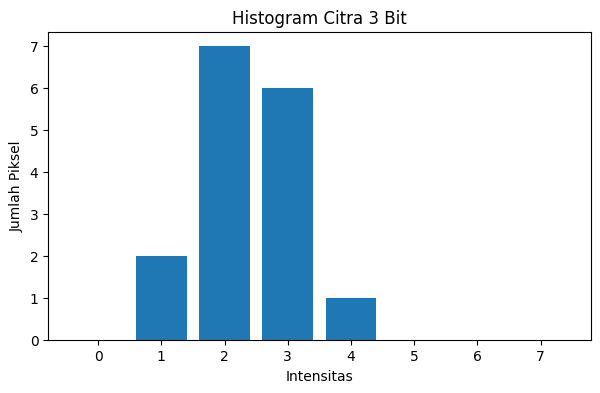


B. PEREGANGAN KONTRAS
Matriks hasil:
[[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]

C. EKUALISASI HISTOGRAM
 r | n | PDF | CDF | 7 x CDF | s
 0 |  0 | 0.0000 | 0.0000 | 0.0000 | 0
 1 |  2 | 0.1250 | 0.1250 | 0.8750 | 1
 2 |  7 | 0.4375 | 0.5625 | 3.9375 | 4
 3 |  6 | 0.3750 | 0.9375 | 6.5625 | 7
 4 |  1 | 0.0625 | 1.0000 | 7.0000 | 7
 5 |  0 | 0.0000 | 1.0000 | 7.0000 | 7
 6 |  0 | 0.0000 | 1.0000 | 7.0000 | 7
 7 |  0 | 0.0000 | 1.0000 | 7.0000 | 7

Matriks hasil ekualisasi:
[[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]

D. OPERASI TITIK
Negatif r=60: 195
Kontras r=120: 138
Kontras r=210: 255
Gamma 0.6, r=100: 145.42
Gamma 1.8, r=100: 47.29


In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Matriks citra 3 bit (L = 8)
M = np.array([
    [1, 2, 2, 3],
    [2, 2, 3, 3],
    [1, 2, 3, 4],
    [2, 3, 3, 2]
])

# A. Histogram
hist = np.bincount(M.flatten(), minlength=8)

print("A. HISTOGRAM")
for r, n in enumerate(hist):
    print(f"Intensitas {r}: {n} piksel")

plt.figure(figsize=(7, 4))
plt.bar(range(8), hist)
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")
plt.title("Histogram Citra 3 Bit")
plt.xticks(range(8))
plt.show()


# B. Peregangan Kontras
rmin = M.min()
rmax = M.max()

M_regang = np.rint(
    (M - rmin) / (rmax - rmin) * 7
).astype(int)

print("\nB. PEREGANGAN KONTRAS")
print("Matriks hasil:")
print(M_regang)


# C. Ekualisasi Histogram
pdf = hist / M.size
cdf = np.cumsum(pdf)
skala = 7 * cdf
s = np.rint(skala).astype(int)

print("\nC. EKUALISASI HISTOGRAM")
print(" r | n | PDF | CDF | 7 x CDF | s")
for r in range(8):
    print(
        f"{r:2d} | {hist[r]:2d} | "
        f"{pdf[r]:.4f} | {cdf[r]:.4f} | "
        f"{skala[r]:.4f} | {s[r]}"
    )

M_ekualisasi = s[M]

print("\nMatriks hasil ekualisasi:")
print(M_ekualisasi)


# D. Operasi Titik 8 Bit
print("\nD. OPERASI TITIK")

# Negatif
r = 60
print("Negatif r=60:", 255 - r)

# Kontras
for r in [120, 210]:
    hasil = np.clip(1.4 * r - 30, 0, 255)
    print(f"Kontras r={r}: {hasil:.0f}")

# Koreksi gamma
for gamma in [0.6, 1.8]:
    r = 100
    hasil = 255 * (r / 255) ** gamma
    print(f"Gamma {gamma}, r=100: {hasil:.2f}")


# 3.2 Diagnosis Mutu

teh_041.png normal {'rerata': 177.4, 'simpangan_baku': 42.4, 'min': 68, 'maks': 222, 'persen_gelap': 0.0, 'persen_terang': 7.4}
teh_042.png gelap {'rerata': 138.6, 'simpangan_baku': 50.3, 'min': 13, 'maks': 193, 'persen_gelap': 16.3, 'persen_terang': 0.0}
teh_043.png terang {'rerata': 216.7, 'simpangan_baku': 24.0, 'min': 139, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 79.9}
teh_044.png kontras_rendah {'rerata': 155.3, 'simpangan_baku': 14.8, 'min': 109, 'maks': 187, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png bayangan {'rerata': 123.1, 'simpangan_baku': 55.5, 'min': 19, 'maks': 249, 'persen_gelap': 3.2, 'persen_terang': 9.4}


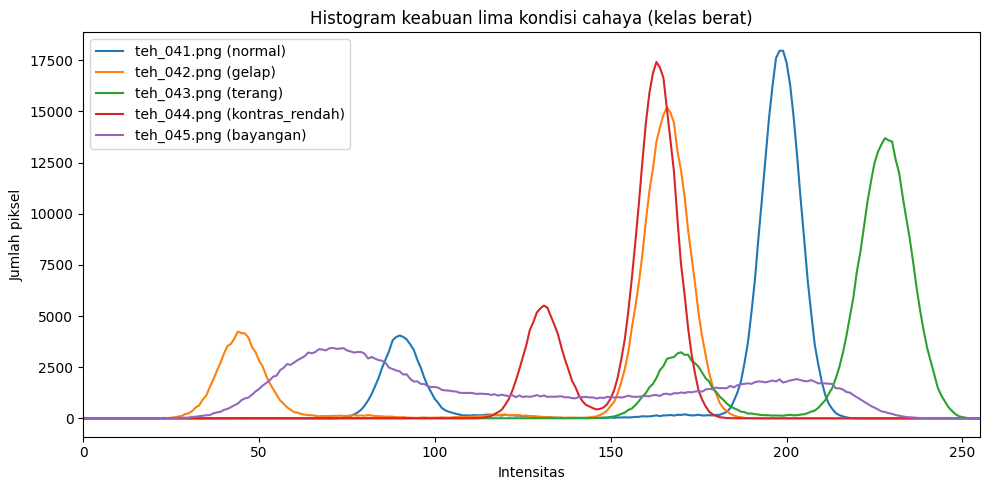

In [3]:
# Statistik dan histogram untuk diagnosis
from utils_cv import statistik

daftar = {
    "teh_041.png": "normal",
    "teh_042.png": "gelap",
    "teh_043.png": "terang",
    "teh_044.png": "kontras_rendah",
    "teh_045.png": "bayangan",
}

plt.figure(figsize=(10, 5))

for nama, kondisi in daftar.items():

    gray = cv2.cvtColor(
        cv2.imread(os.path.join(DATA_DIR, "citra", nama)),
        cv2.COLOR_BGR2GRAY
    )

    print(nama, kondisi, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=f"{nama} ({kondisi})")

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.title("Histogram keabuan lima kondisi cahaya (kelas berat)")
plt.xlim(0, 255)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b3_histogram_5kondisi.png"), dpi=150, bbox_inches="tight")
plt.show()

teh_021.png normal {'rerata': 163.5, 'simpangan_baku': 38.8, 'min': 65, 'maks': 232, 'persen_gelap': 0.0, 'persen_terang': 1.7}
teh_022.png gelap {'rerata': 115.6, 'simpangan_baku': 32.8, 'min': 19, 'maks': 168, 'persen_gelap': 3.4, 'persen_terang': 0.0}
teh_023.png terang {'rerata': 208.8, 'simpangan_baku': 27.1, 'min': 124, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 76.1}
teh_024.png kontras_rendah {'rerata': 156.8, 'simpangan_baku': 15.3, 'min': 98, 'maks': 199, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png bayangan {'rerata': 125.1, 'simpangan_baku': 54.7, 'min': 22, 'maks': 246, 'persen_gelap': 2.0, 'persen_terang': 10.2}


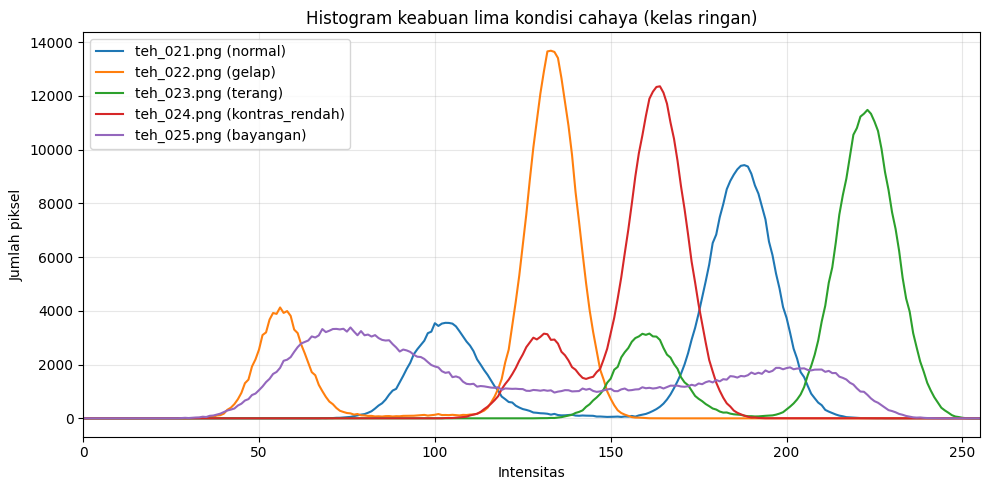

In [4]:
# Statistik dan Histogram Kelas Ringan
daftar_ringan = {
    "teh_021.png": "normal",
    "teh_022.png": "gelap",
    "teh_023.png": "terang",
    "teh_024.png": "kontras_rendah",
    "teh_025.png": "bayangan",
}

plt.figure(figsize=(10, 5))

for nama, kondisi in daftar_ringan.items():
    img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    print(nama, kondisi, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=f"{nama} ({kondisi})")

plt.title("Histogram keabuan lima kondisi cahaya (kelas ringan)")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.xlim(0, 255)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b3_histogram_ringan.png"), dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Tabel 9 - Statistik dan diagnosis mutu citra lima kondisi cahaya

daftar_tabel9 = [
    ("teh_041.png", "Berat", "normal"),
    ("teh_042.png", "Berat", "gelap"),
    ("teh_043.png", "Berat", "terang"),
    ("teh_044.png", "Berat", "kontras_rendah"),
    ("teh_045.png", "Berat", "bayangan"),
    ("teh_021.png", "Ringan", "normal"),
    ("teh_022.png", "Ringan", "gelap"),
    ("teh_023.png", "Ringan", "terang"),
    ("teh_024.png", "Ringan", "kontras_rendah"),
    ("teh_025.png", "Ringan", "bayangan"),
]

# Diagnosis dan usulan perbaikan per kondisi (tulis ulang dengan kalimat sendiri)
diagnosis = {
    "normal": ("Sebaran intensitas lebar, mutu baik",
               "Tidak perlu perbaikan besar"),
    "gelap": ("Histogram menumpuk di intensitas rendah",
              "Gamma < 1 untuk mencerahkan"),
    "terang": ("Histogram menumpuk di intensitas tinggi, banyak piksel jenuh",
               "Gamma > 1 untuk menggelapkan"),
    "kontras_rendah": ("Rentang intensitas sempit, simpangan baku kecil",
                       "Peregangan kontras atau CLAHE"),
    "bayangan": ("Histogram bimodal karena pencahayaan tidak merata",
                 "CLAHE (perbaikan lokal), bukan ekualisasi global"),
}

baris = []
for nama, kelas, kondisi in daftar_tabel9:
    gray = cv2.cvtColor(
        cv2.imread(os.path.join(DATA_DIR, "citra", nama)),
        cv2.COLOR_BGR2GRAY
    )
    s = statistik(gray)
    baris.append([
        nama.replace(".png", ""), kelas, kondisi,
        s["rerata"], s["simpangan_baku"], s["min"], s["maks"],
        s["persen_gelap"], s["persen_terang"],
        diagnosis[kondisi][0], diagnosis[kondisi][1],
    ])

kolom = [
    "Citra", "Kelas", "Kondisi Cahaya",
    "Rerata", "Simpangan Baku", "Min", "Maks",
    "Persen Gelap (%)", "Persen Terang (%)",
    "Diagnosis", "Usulan Perbaikan",
]

tabel9 = pd.DataFrame(baris, columns=kolom)

print("TABEL 9. DIAGNOSIS MUTU CITRA LIMA KONDISI CAHAYA")
display(tabel9)

# Simpan tabel ke CSV
tabel9.to_csv(
    os.path.join(HASIL_DIR, "b3_tabel9_statistik.csv"),
    index=False
)

TABEL 9. DIAGNOSIS MUTU CITRA LIMA KONDISI CAHAYA


,Citra,Kelas,Kondisi Cahaya,Rerata,Simpangan Baku,Min,Maks,Persen Gelap (%),Persen Terang (%),Diagnosis,Usulan Perbaikan
0,teh_041,Berat,normal,177.4,42.4,68,222,0.0,7.4,"Sebaran intensitas lebar, mutu baik",Tidak perlu perbaikan besar
1,teh_042,Berat,gelap,138.6,50.3,13,193,16.3,0.0,Histogram menumpuk di intensitas rendah,Gamma < 1 untuk mencerahkan
2,teh_043,Berat,terang,216.7,24.0,139,254,0.0,79.9,"Histogram menumpuk di intensitas tinggi, banya...",Gamma > 1 untuk menggelapkan
3,teh_044,Berat,kontras_rendah,155.3,14.8,109,187,0.0,0.0,"Rentang intensitas sempit, simpangan baku kecil",Peregangan kontras atau CLAHE
4,teh_045,Berat,bayangan,123.1,55.5,19,249,3.2,9.4,Histogram bimodal karena pencahayaan tidak merata,"CLAHE (perbaikan lokal), bukan ekualisasi global"
5,teh_021,Ringan,normal,163.5,38.8,65,232,0.0,1.7,"Sebaran intensitas lebar, mutu baik",Tidak perlu perbaikan besar
6,teh_022,Ringan,gelap,115.6,32.8,19,168,3.4,0.0,Histogram menumpuk di intensitas rendah,Gamma < 1 untuk mencerahkan
7,teh_023,Ringan,terang,208.8,27.1,124,254,0.0,76.1,"Histogram menumpuk di intensitas tinggi, banya...",Gamma > 1 untuk menggelapkan
8,teh_024,Ringan,kontras_rendah,156.8,15.3,98,199,0.0,0.0,"Rentang intensitas sempit, simpangan baku kecil",Peregangan kontras atau CLAHE
9,teh_025,Ringan,bayangan,125.1,54.7,22,246,2.0,10.2,Histogram bimodal karena pencahayaan tidak merata,"CLAHE (perbaikan lokal), bukan ekualisasi global"


# 3.3 Perbaikan Citra

asli       KB=2.45 sigma=55.5
negatif    KB=2.45 sigma=55.5
cerah+50   KB=2.45 sigma=54.0
kontras    KB=2.46 sigma=78.7
regang     KB=2.56 sigma=80.8
gamma0.5   KB=2.09 sigma=40.2
gamma1.8   KB=3.18 sigma=59.1
ekualisasi KB=1.83 sigma=73.4
CLAHE      KB=2.55 sigma=46.5


,Metode,Parameter,KB,Simpangan Baku
0,asli,-,2.45,55.5
1,negatif,s = 255 - r,2.45,55.5
2,cerah+50,s = r + 50,2.45,54.0
3,kontras,"alpha=1.5, beta=-40",2.46,78.7
4,regang,persentil 2-98 (46-220),2.56,80.8
5,gamma0.5,gamma=0.5,2.09,40.2
6,gamma1.8,gamma=1.8,3.18,59.1
7,ekualisasi,global,1.83,73.4
8,CLAHE,"clip=2.0, tile=8x8",2.55,46.5


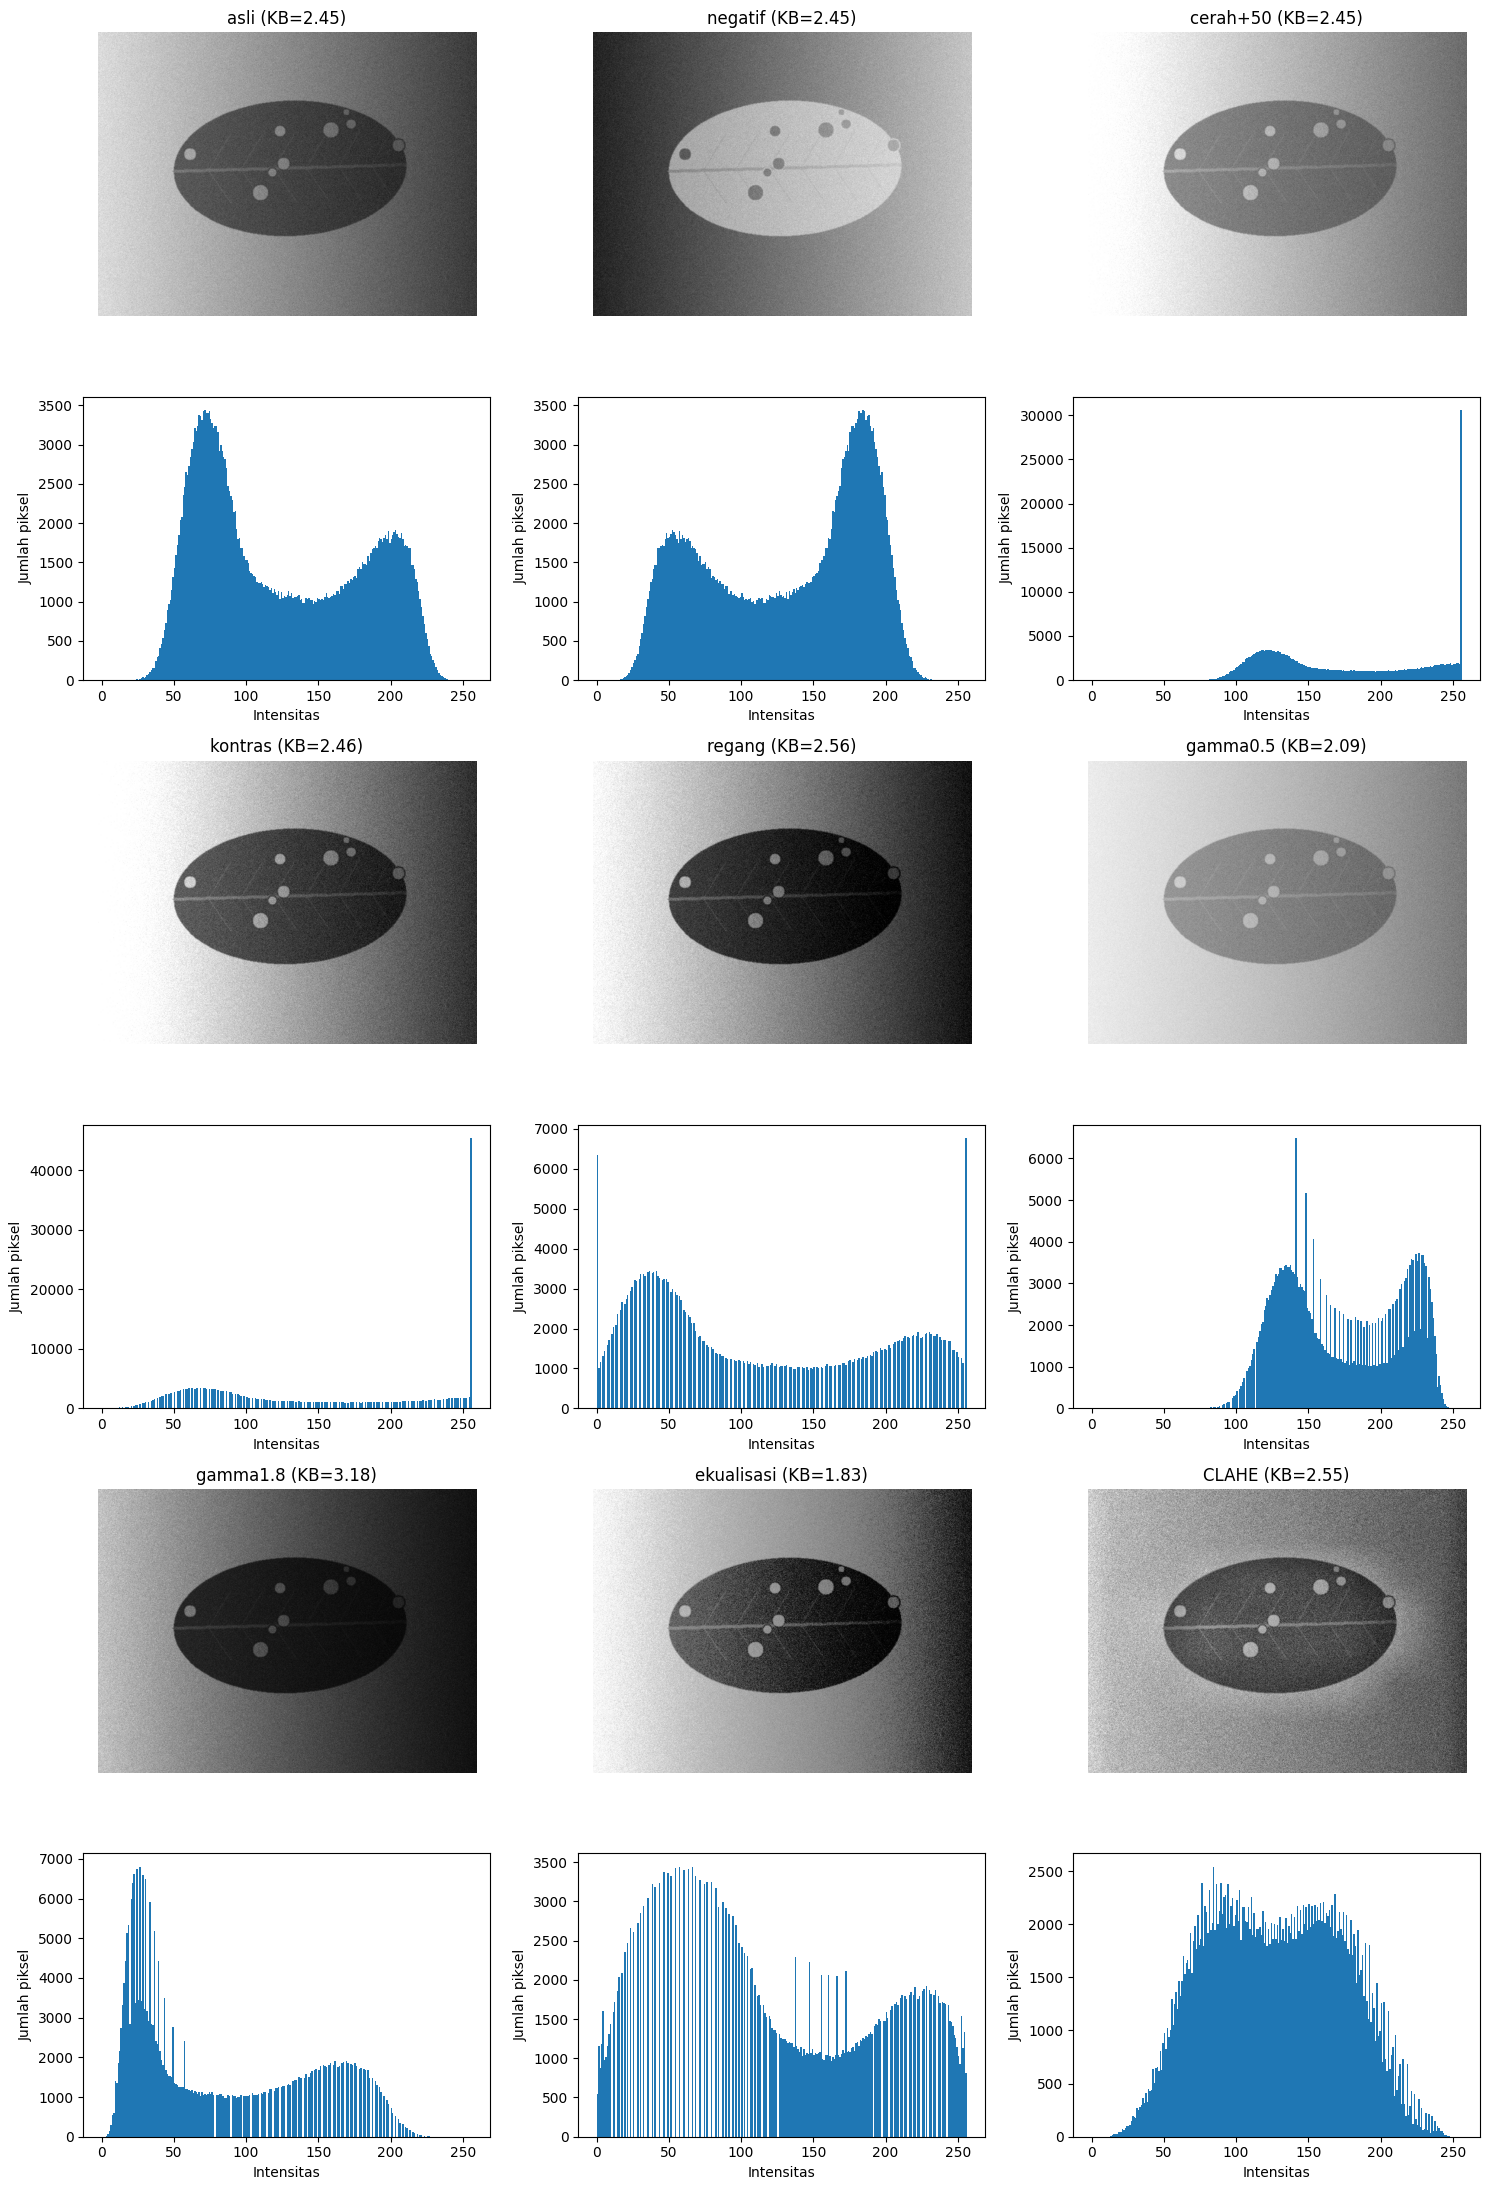

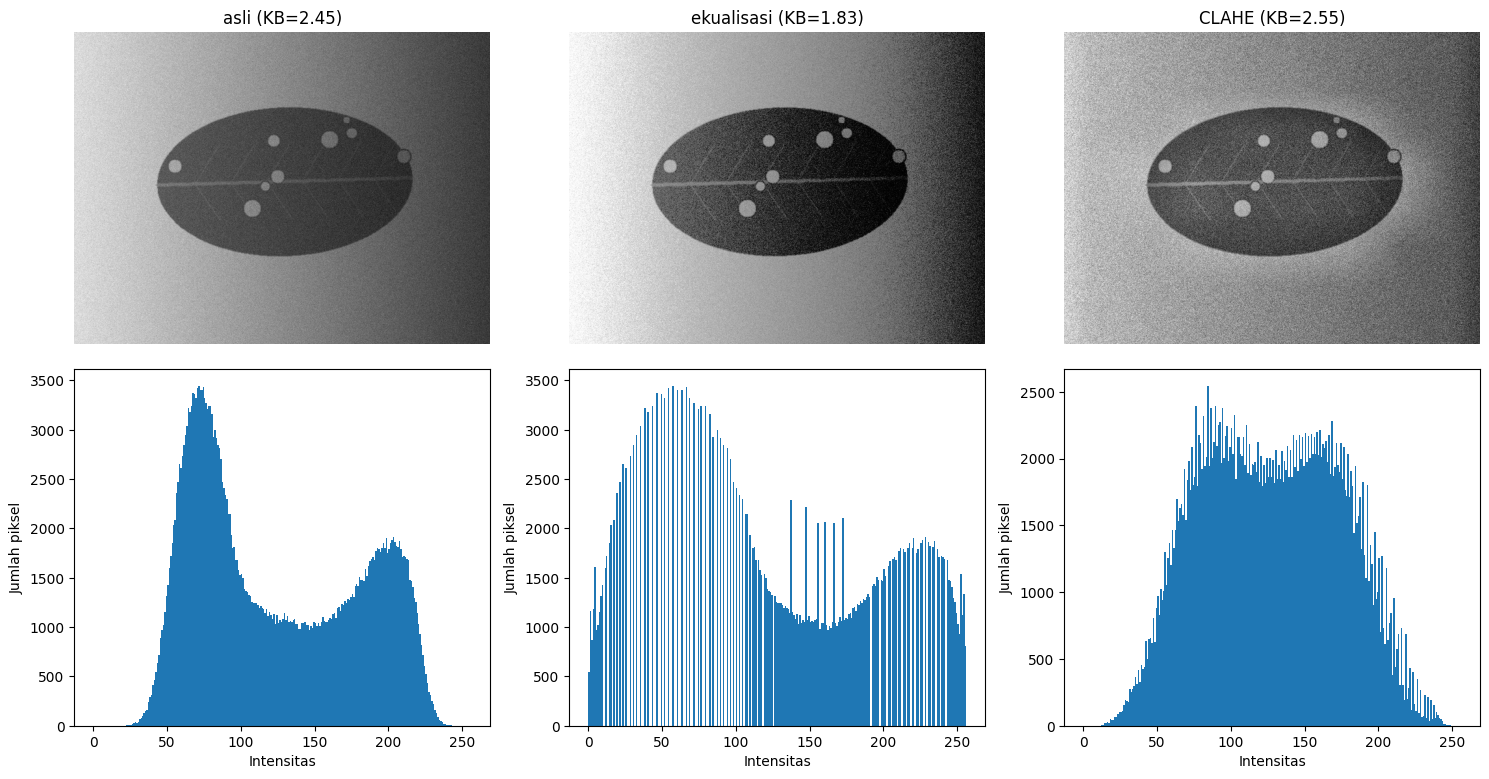

In [6]:
# Perbaikan Citra Kondisi Bayangan
nama = "teh_045.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Fungsi koreksi gamma
def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

# Peregangan persentil 2 dan 98
rmin, rmax = np.percentile(gray, (2, 98))

# Berbagai metode perbaikan citra
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip(
        (gray.astype(float) - rmin) / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(gray)
}

# Parameter setiap metode (kolom "Parameter" pada Tabel 10)
parameter = {
    "asli": "-",
    "negatif": "s = 255 - r",
    "cerah+50": "s = r + 50",
    "kontras": "alpha=1.5, beta=-40",
    "regang": f"persentil 2-98 ({rmin:.0f}-{rmax:.0f})",
    "gamma0.5": "gamma=0.5",
    "gamma1.8": "gamma=1.8",
    "ekualisasi": "global",
    "CLAHE": "clip=2.0, tile=8x8",
}

# Menghitung KB dan simpangan baku -> Tabel 10
baris = []
for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    print(f"{nm:10s} KB={kb:.2f} sigma={c.std():.1f}")
    baris.append([nm, parameter[nm], round(kb, 2), round(float(c.std()), 1)])

tabel10 = pd.DataFrame(baris, columns=["Metode", "Parameter", "KB", "Simpangan Baku"])
display(tabel10)
tabel10.to_csv(os.path.join(HASIL_DIR, "b3_tabel10.csv"), index=False)

# Panel lengkap: 3 metode per baris, citra di atas dan histogram di bawah
fig, axes = plt.subplots(6, 3, figsize=(15, 22))

for i, (nm, c) in enumerate(hasil.items()):
    baris_img = (i // 3) * 2
    kolom = i % 3

    axes[baris_img, kolom].imshow(c, cmap="gray", vmin=0, vmax=255)
    axes[baris_img, kolom].set_title(f"{nm} (KB={kontras_bercak(c, md, mb):.2f})")
    axes[baris_img, kolom].axis("off")

    axes[baris_img + 1, kolom].hist(c.ravel(), bins=256, range=(0, 256))
    axes[baris_img + 1, kolom].set_xlabel("Intensitas")
    axes[baris_img + 1, kolom].set_ylabel("Jumlah piksel")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b3_perbaikan_bayangan.png"), dpi=150, bbox_inches="tight")
plt.show()

# Panel ringkas seperti Gambar 4: asli, ekualisasi global, CLAHE (untuk slide)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for j, nm in enumerate(["asli", "ekualisasi", "CLAHE"]):
    c = hasil[nm]
    axes[0, j].imshow(c, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"{nm} (KB={kontras_bercak(c, md, mb):.2f})")
    axes[0, j].axis("off")

    axes[1, j].hist(c.ravel(), bins=256, range=(0, 256))
    axes[1, j].set_xlabel("Intensitas")
    axes[1, j].set_ylabel("Jumlah piksel")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b3_asli_ekualisasi_clahe.png"), dpi=150, bbox_inches="tight")
plt.show()

# 3.4 Parameter CLAHE dan Citra Warna

In [7]:
# Eksperimen Parameter CLAHE
nama = "teh_045.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

hasil_clahe = []

for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        clahe = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        )

        c = clahe.apply(gray)
        kb = kontras_bercak(c, md, mb)

        hasil_clahe.append([clip, tile, round(kb, 2)])

tabel_clahe = pd.DataFrame(
    hasil_clahe,
    columns=["clipLimit", "tileGridSize", "KB"]
)

print("TABEL EKSPERIMEN PARAMETER CLAHE")
display(tabel_clahe)

tabel_clahe.to_csv(
    os.path.join(HASIL_DIR, "b3_4_eksperimen_clahe.csv"),
    index=False
)

# Versi matriks 3x3 untuk laporan: baris = clipLimit, kolom = tileGridSize
matriks_clahe = tabel_clahe.pivot(index="clipLimit", columns="tileGridSize", values="KB")
print("\nKB CLAHE (baris = clipLimit, kolom = tileGridSize)")
display(matriks_clahe)

matriks_clahe.to_csv(os.path.join(HASIL_DIR, "b3_4_matriks_clahe.csv"))

TABEL EKSPERIMEN PARAMETER CLAHE


,clipLimit,tileGridSize,KB
0,1.0,4,3.18
1,1.0,8,2.85
2,1.0,16,2.76
3,2.0,4,2.81
4,2.0,8,2.55
5,2.0,16,2.39
6,4.0,4,2.23
7,4.0,8,2.06
8,4.0,16,1.88



KB CLAHE (baris = clipLimit, kolom = tileGridSize)


tileGridSize,4,8,16
clipLimit,,,
1.0,3.18,2.85,2.76
2.0,2.81,2.55,2.39
4.0,2.23,2.06,1.88


,Metode,Pergeseran Hue rerata (daun),KB kanal R
0,Asli,0.00,4.98
1,CLAHE kanal V,0.07,5.96
2,CLAHE tiap kanal BGR,19.37,3.26


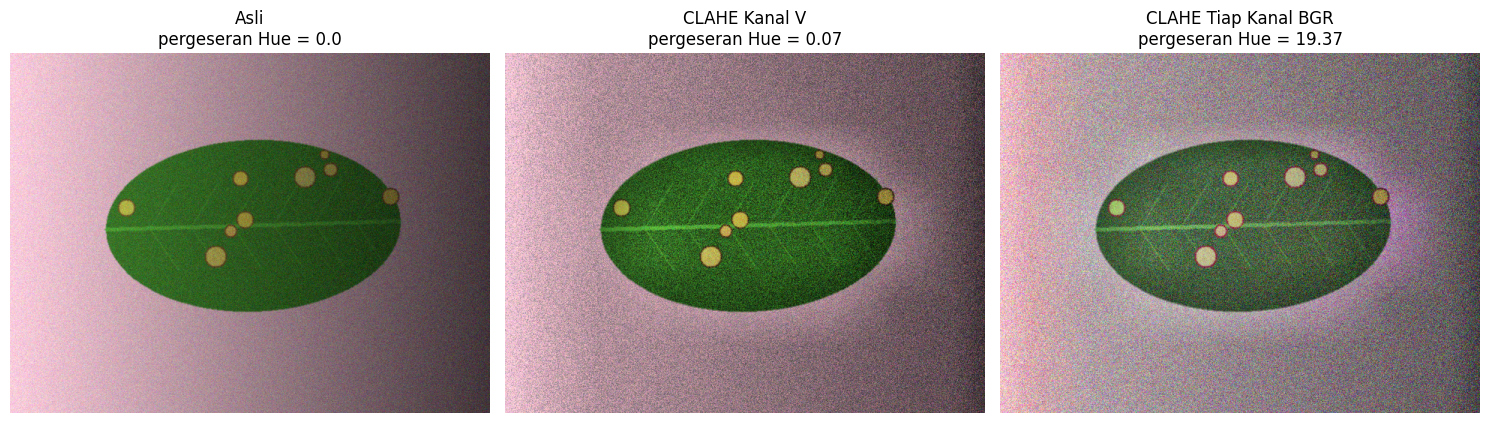

In [8]:
# Perbandingan CLAHE Kanal V dan BGR
nama = "teh_045.png"

img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# CLAHE pada kanal V
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

# CLAHE pada setiap kanal BGR
via_bgr = cv2.merge([
    clahe.apply(c) for c in cv2.split(img)
])

# Bukti kuantitatif: pergeseran Hue pada area daun dan KB kanal R
def geser_hue(asli, hasil, mask):
    """Rerata selisih Hue (0-179, sifatnya melingkar) pada area mask."""
    h1 = cv2.cvtColor(asli, cv2.COLOR_BGR2HSV)[:, :, 0].astype(int)
    h2 = cv2.cvtColor(hasil, cv2.COLOR_BGR2HSV)[:, :, 0].astype(int)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)
    return d[mask > 0].mean()

bukti = []
for nm, c in [("Asli", img), ("CLAHE kanal V", via_v), ("CLAHE tiap kanal BGR", via_bgr)]:
    bukti.append([
        nm,
        round(geser_hue(img, c, md), 2),
        round(kontras_bercak(c[:, :, 2], md, mb), 2),
    ])

tabel_clahe_warna = pd.DataFrame(
    bukti, columns=["Metode", "Pergeseran Hue rerata (daun)", "KB kanal R"]
)
display(tabel_clahe_warna)
tabel_clahe_warna.to_csv(os.path.join(HASIL_DIR, "b3_clahe_v_vs_bgr.csv"), index=False)

# Menampilkan hasil perbandingan
gambar = [img, via_v, via_bgr]
judul = ["Asli", "CLAHE Kanal V", "CLAHE Tiap Kanal BGR"]

plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(gambar[i], cv2.COLOR_BGR2RGB))
    plt.title(f"{judul[i]}\npergeseran Hue = {bukti[i][1]}")
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b3_clahe_v_vs_bgr.png"), dpi=150, bbox_inches="tight")
plt.show()

# 3.5 Perbaikan Citra Pada Empat Kondisi Cahaya

KB SEMUA METODE PER CITRA


,citra,kelas,kondisi,asli,Cerah +50,Kontras,Regang,Gamma 0.5,Gamma 1.8,Ekualisasi,CLAHE
0,teh_042.png,berat,gelap,5.19,5.19,5.21,5.49,4.19,7.13,1.07,2.58
1,teh_022.png,ringan,gelap,2.00,2.00,2.01,2.39,1.59,2.64,0.57,1.11
2,teh_043.png,berat,terang,3.13,2.54,1.99,3.38,2.94,3.39,1.66,1.48
3,teh_023.png,ringan,terang,2.88,2.58,2.23,3.06,2.71,3.16,1.86,1.97
4,teh_044.png,berat,kontras_rendah,2.52,2.52,2.52,2.71,2.42,2.63,1.91,1.85
5,teh_024.png,ringan,kontras_rendah,1.10,1.10,1.10,1.22,1.06,1.17,1.53,0.81
6,teh_045.png,berat,bayangan,2.45,2.45,2.46,2.56,2.09,3.18,1.83,2.55
7,teh_025.png,ringan,bayangan,0.19,0.19,0.19,0.16,0.21,0.16,0.14,0.99



PERBAIKAN TERPILIH PER KONDISI


,citra,kelas,kondisi,metode,KB_sebelum,KB_sesudah
0,teh_042.png,berat,gelap,Gamma 0.5,5.19,4.19
1,teh_022.png,ringan,gelap,Gamma 0.5,2.00,1.59
2,teh_043.png,berat,terang,Gamma 1.8,3.13,3.39
3,teh_023.png,ringan,terang,Gamma 1.8,2.88,3.16
4,teh_044.png,berat,kontras_rendah,Regang,2.52,2.71
5,teh_024.png,ringan,kontras_rendah,Regang,1.10,1.22
6,teh_045.png,berat,bayangan,CLAHE,2.45,2.55
7,teh_025.png,ringan,bayangan,CLAHE,0.19,0.99


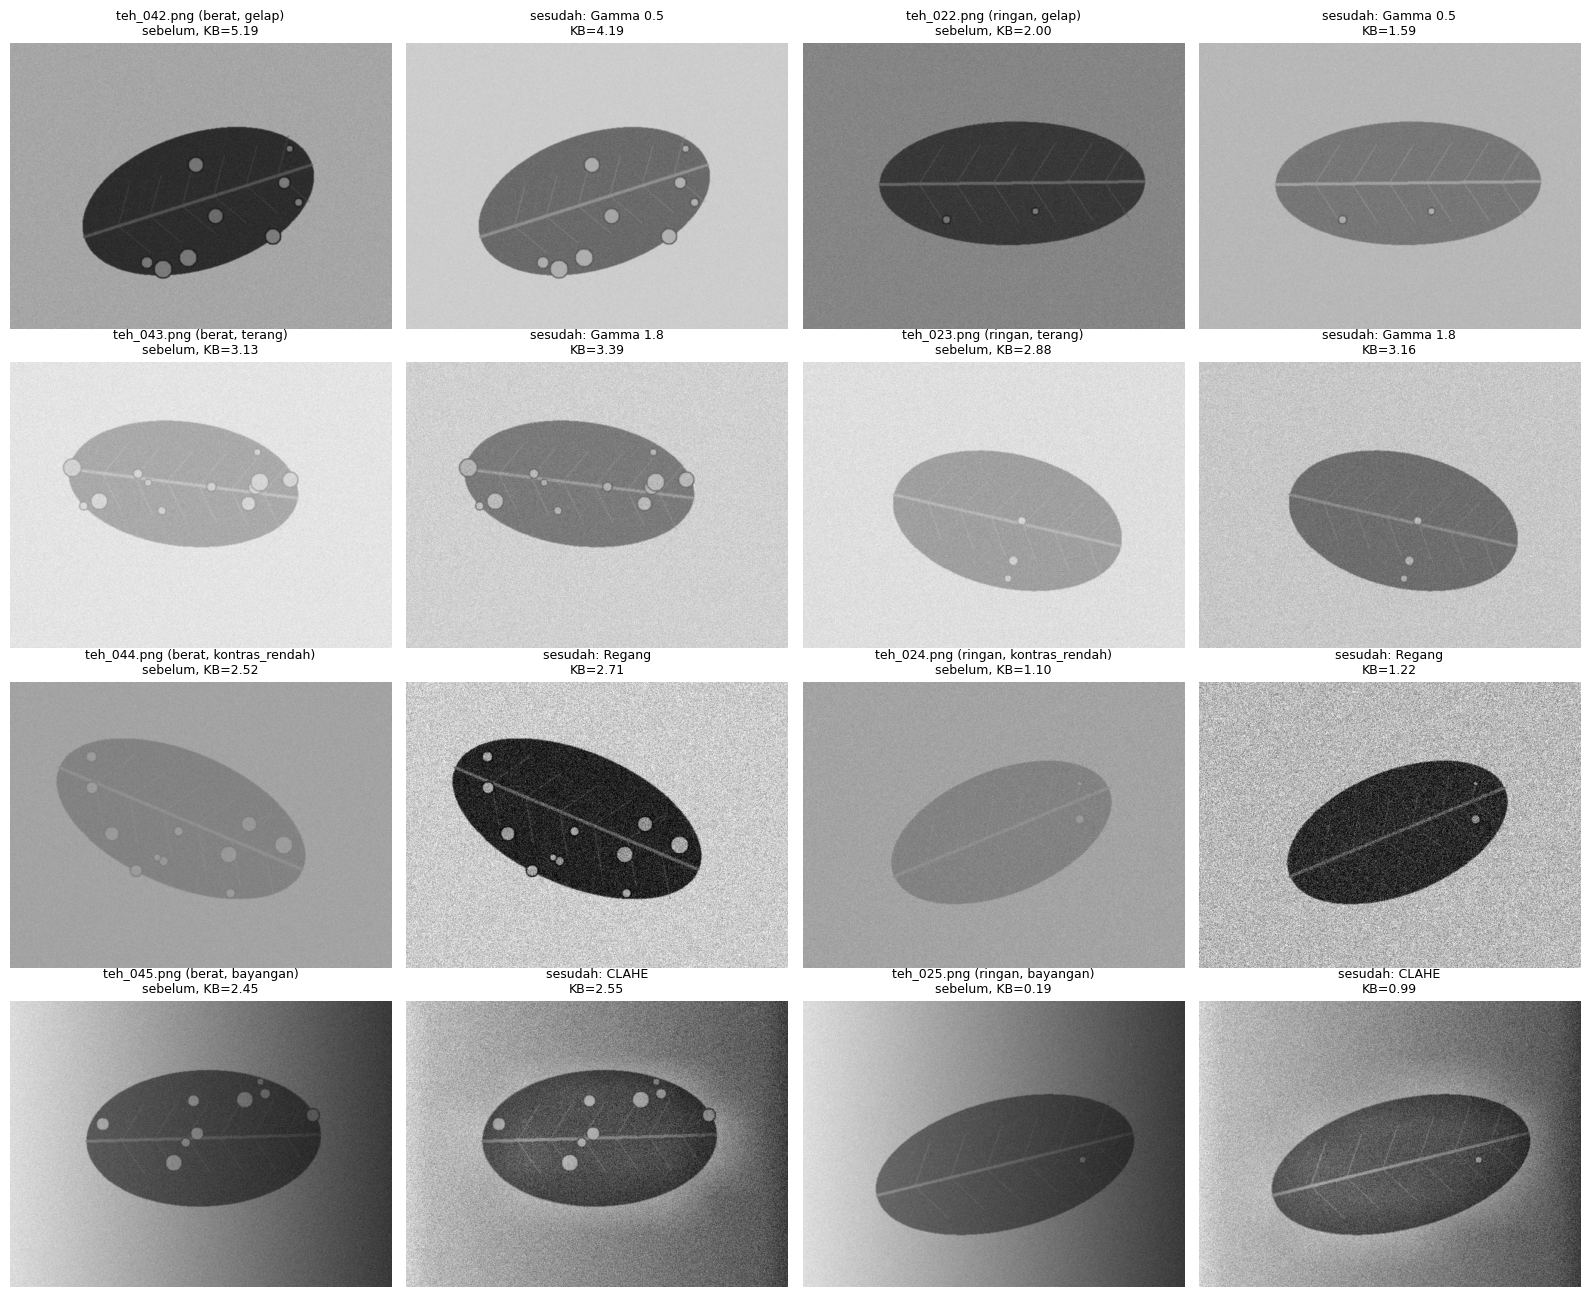

In [9]:
# Perbaikan Citra pada Empat Kondisi Cahaya
pasangan = {
    "gelap": ["teh_042.png", "teh_022.png"],
    "terang": ["teh_043.png", "teh_023.png"],
    "kontras_rendah": ["teh_044.png", "teh_024.png"],
    "bayangan": ["teh_045.png", "teh_025.png"],
}

# Metode dipilih berdasarkan diagnosis histogram (Tabel 9), bukan dari mask acuan.
# Ubah bila tabel KB kandidat di bawah menunjukkan alasan kuat untuk memilih lain.
pilihan = {
    "gelap": "Gamma 0.5",
    "terang": "Gamma 1.8",
    "kontras_rendah": "Regang",
    "bayangan": "CLAHE",
}

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

def metode_perbaikan(gray):
    rmin, rmax = np.percentile(gray, (2, 98))

    hasil = {
        "Cerah +50": cv2.add(gray, 50),
        "Kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
        "Regang": np.clip(
            (gray.astype(float) - rmin) /
            max(rmax - rmin, 1) * 255, 0, 255
        ).astype(np.uint8),
        "Gamma 0.5": cv2.LUT(gray, gamma_lut(0.5)),
        "Gamma 1.8": cv2.LUT(gray, gamma_lut(1.8)),
        "Ekualisasi": cv2.equalizeHist(gray),
        "CLAHE": cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(gray)
    }

    return hasil

baris_kandidat = []   # KB semua metode (bukti pendukung)
baris_ringkas = []    # KB sebelum dan sesudah metode terpilih
panel = []            # data untuk gambar

for kondisi, daftar_citra in pasangan.items():
    for nama in daftar_citra:
        img = cv2.imread(os.path.join(DATA_DIR, "citra", nama))
        md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
        mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        kelas = "berat" if nama in ("teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png") else "ringan"
        kandidat = metode_perbaikan(gray)

        kb_sebelum = kontras_bercak(gray, md, mb)
        baris_kb = {"citra": nama, "kelas": kelas, "kondisi": kondisi, "asli": round(kb_sebelum, 2)}
        for m, c in kandidat.items():
            baris_kb[m] = round(kontras_bercak(c, md, mb), 2)
        baris_kandidat.append(baris_kb)

        metode = pilihan[kondisi]
        sesudah = kandidat[metode]
        kb_sesudah = kontras_bercak(sesudah, md, mb)

        baris_ringkas.append([nama, kelas, kondisi, metode,
                              round(kb_sebelum, 2), round(kb_sesudah, 2)])
        panel.append((nama, kelas, kondisi, metode, gray, sesudah, kb_sebelum, kb_sesudah))

# Tabel KB semua kandidat (bukti pemilihan metode)
tabel_kandidat = pd.DataFrame(baris_kandidat)
print("KB SEMUA METODE PER CITRA")
display(tabel_kandidat)
tabel_kandidat.to_csv(os.path.join(HASIL_DIR, "b3_5_kb_kandidat.csv"), index=False)

# Tabel ringkas metode terpilih
tabel_35 = pd.DataFrame(baris_ringkas, columns=[
    "citra", "kelas", "kondisi", "metode", "KB_sebelum", "KB_sesudah"])
print("\nPERBAIKAN TERPILIH PER KONDISI")
display(tabel_35)
tabel_35.to_csv(os.path.join(HASIL_DIR, "b3_5_perbaikan_4kondisi.csv"), index=False)

# Panel 4x4: tiap baris satu kondisi -> berat sebelum, berat sesudah, ringan sebelum, ringan sesudah
fig, axes = plt.subplots(4, 4, figsize=(16, 13))

for i, (nama, kelas, kondisi, metode, sebelum, sesudah, kb0, kb1) in enumerate(panel):
    r = i // 2
    k = (i % 2) * 2

    axes[r, k].imshow(sebelum, cmap="gray", vmin=0, vmax=255)
    axes[r, k].set_title(f"{nama} ({kelas}, {kondisi})\nsebelum, KB={kb0:.2f}", fontsize=9)
    axes[r, k].axis("off")

    axes[r, k + 1].imshow(sesudah, cmap="gray", vmin=0, vmax=255)
    axes[r, k + 1].set_title(f"sesudah: {metode}\nKB={kb1:.2f}", fontsize=9)
    axes[r, k + 1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b3_4kondisi.png"), dpi=150, bbox_inches="tight")
plt.show()